# C06 – Xuất xứ hàng hóa trong cửa hàng TP.HCM
**Q4.** Trong cửa hàng tại TP.HCM, bao nhiêu hàng là "Made in Vietnam", xét theo ngành hàng (phần HS) và mức giá?

In [33]:
# ===== SETUP CHUNG  =====
import sys, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
from house_style.house_style import (apply_style, HS_ORDER, PARTNER_COLORS, OTHER_COLOR,
                                     SOURCE, DIRECT_LABEL, declutter, COUNTRY_COLORS)

OUT = ROOT / "outputs" / "core_charts" / "C06"
OUT.mkdir(parents=True, exist_ok=True)

VN = "Việt Nam"
VN_COLOR = COUNTRY_COLORS["VNM"]   
NGUON = "Nguồn: Khảo sát cửa hàng TP.HCM (survey_final.csv), 398 mẫu hàng tại các cửa hàng đã chọn"
ISO = {"Trung Quốc": "CHN", "Thái Lan": "THA", "Nhật Bản": "JPN", "Hàn Quốc": "KOR", "Mỹ": "USA"}
FALLBACK = ["#E69F00", "#56B4E9", "#F0E442", "#999999"]

df = pd.read_csv(ROOT / "data" / "clean" / "survey_final.csv", encoding="utf-8-sig")

def text_color(c):                      # chữ trắng trên nền tối, chữ đen trên nền sáng
    r, g, b = to_rgb(c)
    return "white" if 0.299*r + 0.587*g + 0.114*b < 0.55 else "#222222"

def hs_label(s, n):                     # nhãn trục: chỉ mã phần HS + n
    return f"{s} (n={n})"

def country_color(c, i=0):              # màu nước theo house_style, thiếu thì dùng màu dự phòng
    return PARTNER_COLORS.get(ISO.get(c), FALLBACK[i % len(FALLBACK)])

print(df.shape)

(398, 34)


### C06A – Cơ cấu xuất xứ theo ngành hàng (phần HS)
- **Câu hỏi phụ (Q4.1):** So tỷ trọng nước xuất xứ giữa các phần HS.
- **Task:** So sánh (compare) tỷ trọng nước xuất xứ giữa các phần HS.
- **Dạng biểu đồ:** 100% stacked horizontal bar.
- **Lý do chọn dạng:** 100% stacked bar so cơ cấu xuất xứ, đọc được trực tiếp tỷ lệ Việt Nam.
- **Dữ liệu:** `data/clean/survey_final.csv` — `record_id, hs2022_section, origin_country, made_in_vietnam, verify_status`; lọc: sản phẩm có phần HS và xuất xứ hợp lệ.

In [ ]:
# [C06A] HÀM XỬ LÝ DỮ LIỆU
def prep_c06a(df, hs_sections=None, top_n=3, only_verified=False):
    """Tỷ trọng (%) nước xuất xứ theo phần HS. Top-N nước ngoài VN tính trên TOÀN MẪU, còn lại gộp 'Khác'."""
    d = df.dropna(subset=["hs2022_section", "origin_country"])
    if only_verified:
        d = d[d.verify_status == "OK"]
    top = d.loc[d.origin_country != VN, "origin_country"].value_counts().head(top_n).index.tolist()
    d = d.assign(nhom=np.where(d.origin_country.isin([VN] + top), d.origin_country, "Khác"))
    if hs_sections:
        d = d[d.hs2022_section.isin(hs_sections)]
    order = [s for s in HS_ORDER if s in set(d.hs2022_section)]          # xếp I → XX
    cols = [VN] + top + ["Khác"]
    ct = pd.crosstab(d.hs2022_section, d.nhom).reindex(index=order, columns=cols, fill_value=0)
    n = ct.sum(axis=1)
    return ct.div(n, axis=0) * 100, n, top, d

In [ ]:
# [C06A] HÀM VẼ + ACTION TITLE + HOUSE STYLE
def plot_c06a(pct, n, title, vn_color=VN_COLOR, min_label=7, figsize=(11, 7.5), note=""):
    cols = list(pct.columns)
    colors = {VN: vn_color, "Khác": OTHER_COLOR}
    colors.update({c: country_color(c, i) for i, c in enumerate(cols[1:-1])})
    with apply_style():
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        y = np.arange(len(pct)); left = np.zeros(len(pct))
        for c in cols:
            w = pct[c].values
            ax.barh(y, w, left=left, color=colors[c], label=c, height=0.7, edgecolor="white", linewidth=0.8)
            for yi, (l, wi) in enumerate(zip(left, w)):
                if wi >= min_label:                                  # chỉ ghi % khi đủ rộng
                    ax.text(l + wi/2, yi, f"{wi:.1f}%", ha="center", va="center",
                            color=text_color(colors[c]), **DIRECT_LABEL)
            left += w
        ax.set_yticks(y, [hs_label(s, n[s]) for s in pct.index])
        ax.invert_yaxis()                                            # I ở trên cùng
        ax.set_xlim(0, 100)
        ax.set_xlabel("Tỷ trọng sản phẩm theo nước xuất xứ (%)")
        ax.set_ylabel("Phần HS")
        declutter(ax, "x")
        ax.legend(ncol=len(cols), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.suptitle(textwrap.fill(title, 80))                       # ACTION TITLE
        fig.supxlabel(NGUON + note, **SOURCE)
    return fig, ax

Top nước ngoài VN: ['Trung Quốc', 'Thái Lan', 'Nhật Bản'] | n = 398 | cần xác minh: 14


nhom,Việt Nam,Trung Quốc,Thái Lan,Nhật Bản,Khác,n
hs2022_section,,,,,,
I,90.5,4.8,0.0,0.0,4.8,21
II,0.0,0.0,0.0,100.0,0.0,1
IV,60.4,1.9,9.4,1.9,26.4,106
VI,51.3,10.3,12.0,14.5,12.0,117
VII,60.0,40.0,0.0,0.0,0.0,5
VIII,45.5,54.5,0.0,0.0,0.0,11
X,66.7,33.3,0.0,0.0,0.0,9
XI,93.3,0.0,0.0,0.0,6.7,45
XII,66.7,16.7,16.7,0.0,0.0,6


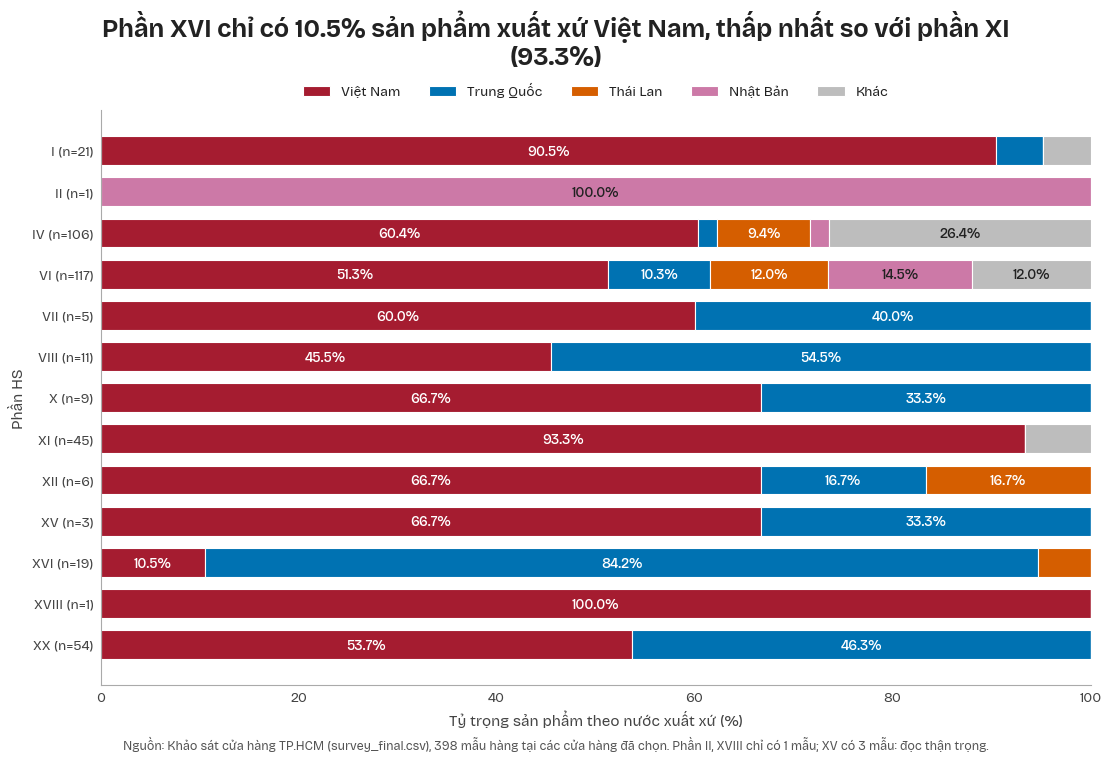

In [ ]:
# [C06A] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU ẢNH
# ---- THAM SỐ  ----
HS_SECTIONS   = None      # None = tất cả; hoặc ["I", "IV", "VI"]
TOP_N         = 3         # số nước ngoài VN hiển thị riêng
ONLY_VERIFIED = False     # True = bỏ mẫu "Cần xác minh"
COLOR_VN      = VN_COLOR  # đổi màu Việt Nam, ví dụ "#D55E00"
MIN_LABEL     = 7         # ngưỡng % tối thiểu để ghi nhãn trong thanh
ACTION_TITLE  = "Phần XVI chỉ có 10.5% sản phẩm xuất xứ Việt Nam, thấp nhất so với phần XI (93.3%)"
NOTE          = ". Phần II, XVIII chỉ có 1 mẫu; XV có 3 mẫu: đọc thận trọng."
FILE_A        = "C06A_co_cau_xuat_xu_theo_hs.png"

pct_c06a, n_c06a, top_c06a, df_c06a = prep_c06a(df, HS_SECTIONS, TOP_N, ONLY_VERIFIED)
print("Top nước ngoài VN:", top_c06a, "| n =", len(df_c06a), "| cần xác minh:", (df_c06a.verify_status != "OK").sum())
display(pct_c06a.round(1).assign(n=n_c06a))

fig_c06a, ax_c06a = plot_c06a(pct_c06a, n_c06a, ACTION_TITLE, COLOR_VN, MIN_LABEL, note=NOTE)
with apply_style():
    fig_c06a.savefig(OUT / FILE_A, dpi=300)
plt.show()

**Insight & kết luận (C06A)**
- Hàng Việt chiếm áp đảo ở phần XI Dệt may (93.3%) và phần I Động vật (90.5%); phần IV (60.4%) và VI (51.3%), hai phần lớn nhất mẫu, có Việt Nam chiếm từ một nửa đến 60%.
- Phần XVI Máy móc, thiết bị điện là ngoại lệ rõ nhất: chỉ 10.5% Việt Nam, Trung Quốc chiếm 84.2%.
- Trung Quốc là nước ngoài xuất hiện nhiều nhất (phần VII, VIII, X, XV, XX từ 33.3% đến 54.5%); Thái Lan, Nhật Bản chủ yếu xuất hiện ở phần IV và VI.

**Hạn chế:** mẫu 398 hàng tại các cửa hàng đã chọn, không suy rộng thị phần TP.HCM. Phần II, XVIII (n=1), XV (n=3), VII, XII, X (n ≤ 9) quá ít mẫu. `origin_country` ≠ `brand_origin`. Mẫu `Cần xác minh` vẫn được giữ trong hình.

### C06B – Tỷ trọng hàng Việt theo mức giá
- **Câu hỏi phụ (Q4.2):** So tỷ trọng hàng Made in Vietnam theo mức giá.
- **Task:** So sánh (compare) tỷ trọng hàng Made in Vietnam theo mức giá.
- **Dạng biểu đồ:** 100% stacked horizontal bar.
- **Lý do chọn dạng:** Chồng 100% thuận tiện so Việt Nam / ngoài Việt Nam ở ba nhóm giá.
- **Dữ liệu:** `data/clean/survey_final.csv` — `record_id, price_tier, made_in_vietnam, origin_country, verify_status, category_clean, price_comparison_unit`; lọc: xuất xứ hợp lệ, mức giá Thấp / Trung bình / Cao (mẫu thiếu tier ghi riêng). Dùng mức giá đã phân theo danh mục và đơn vị so sánh giá, không tự đặt ngưỡng chung.

In [ ]:
# [C06B] HÀM XỬ LÝ DỮ LIỆU
def prep_c06b(df, tiers=("Thấp", "Trung bình", "Cao"), hs_sections=None,
              show_unclassified=True, only_verified=False):
    """% VN / ngoài VN theo mức giá; mẫu không có tier gom thành 'Chưa phân loại'."""
    d = df.dropna(subset=["origin_country"])
    if only_verified:
        d = d[d.verify_status == "OK"]
    if hs_sections:
        d = d[d.hs2022_section.isin(hs_sections)]
    d = d.assign(tier=d.price_tier.where(d.price_tier.isin(tiers), "Chưa phân loại"))
    rows = list(tiers) + (["Chưa phân loại"] if show_unclassified else [])
    g = d.groupby("tier").made_in_vietnam.agg(n="size", vn="sum").reindex(rows).fillna(0)
    g["pct_vn"] = g.vn / g.n * 100
    g["pct_ngoai"] = 100 - g.pct_vn
    return g, d

In [ ]:
# [C06B] HÀM VẼ + ACTION TITLE + HOUSE STYLE
def plot_c06b(g, title, vn_color=VN_COLOR, other_color=OTHER_COLOR, figsize=(10, 5), note=""):
    k = len(g)
    ypos = np.arange(k, dtype=float)
    if g.index[-1] == "Chưa phân loại":
        ypos[-1] += 0.4                                              # tách thanh "Chưa phân loại"
    with apply_style():
        fig, ax = plt.subplots(figsize=figsize, layout="constrained")
        for lab, col, key in [("Việt Nam", vn_color, "pct_vn"), ("Ngoài Việt Nam", other_color, "pct_ngoai")]:
            left = np.zeros(k) if key == "pct_vn" else g.pct_vn.values
            ax.barh(ypos, g[key], left=left, color=col, label=lab, height=0.6, edgecolor="white")
            for yi, v, l in zip(ypos, g[key], left):
                ax.text(l + v/2, yi, f"{v:.1f}%", ha="center", va="center", color=text_color(col), **DIRECT_LABEL)
        ax.set_yticks(ypos, [f"{r} (n={int(g.n[r])})" for r in g.index])
        ax.invert_yaxis()
        ax.set_xlim(0, 100)
        ax.set_xlabel("Tỷ trọng sản phẩm (%)")
        ax.set_ylabel("Mức giá")
        declutter(ax, "x")
        ax.legend(ncol=2, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.suptitle(textwrap.fill(title, 80))                       # ACTION TITLE
        fig.supxlabel(NGUON + note, **SOURCE)
    return fig, ax

n = 398 | cần xác minh: 14


,n,vn,pct_vn,pct_ngoai
tier,,,,
Thấp,119,88,73.9,26.1
Trung bình,93,61,65.6,34.4
Cao,94,44,46.8,53.2
Chưa phân loại,92,44,47.8,52.2


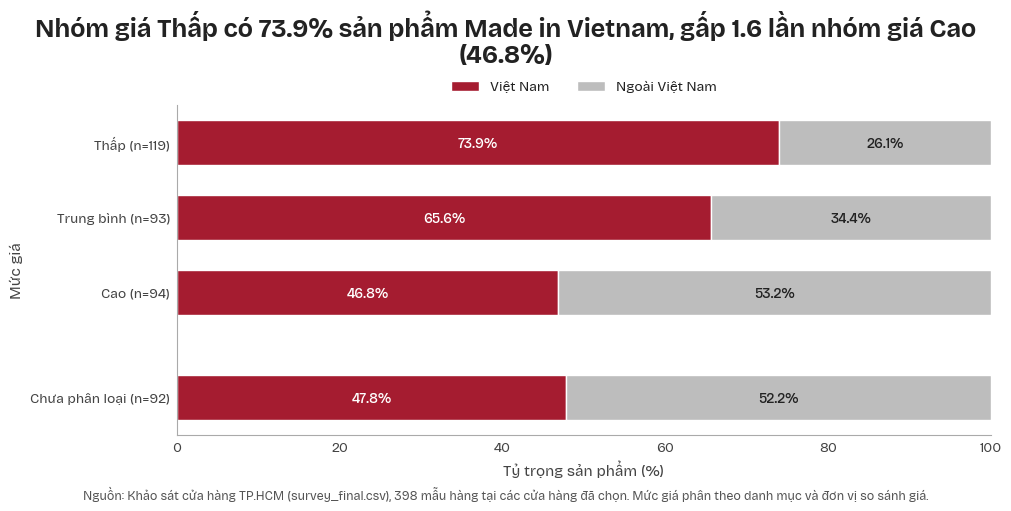

In [ ]:
# [C06B] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU ẢNH
# ---- THAM SỐ ----
TIERS             = ("Thấp", "Trung bình", "Cao")   # thứ tự thanh
HS_SECTIONS_B     = None      # None = tất cả; hoặc ["IV", "VI"] để lọc phần HS
SHOW_UNCLASSIFIED = True      # False = ẩn thanh "Chưa phân loại"
ONLY_VERIFIED_B   = False
COLOR_VN_B        = VN_COLOR
COLOR_OTHER_B     = OTHER_COLOR
ACTION_TITLE_B    = "Nhóm giá Thấp có 73.9% sản phẩm Made in Vietnam, gấp 1.6 lần nhóm giá Cao (46.8%)"
NOTE_B            = ". Mức giá phân theo danh mục và đơn vị so sánh giá."
FILE_B            = "C06B_ty_trong_hang_viet_theo_muc_gia.png"

g_c06b, df_c06b = prep_c06b(df, TIERS, HS_SECTIONS_B, SHOW_UNCLASSIFIED, ONLY_VERIFIED_B)
print("n =", len(df_c06b), "| cần xác minh:", (df_c06b.verify_status != "OK").sum())
display(g_c06b.round(1))

fig_c06b, ax_c06b = plot_c06b(g_c06b, ACTION_TITLE_B, COLOR_VN_B, COLOR_OTHER_B, note=NOTE_B)
with apply_style():
    fig_c06b.savefig(OUT / FILE_B, dpi=300)
plt.show()

**Insight & kết luận (C06B)**
- Tỷ trọng hàng Việt giảm dần khi mức giá tăng: Thấp 73.9% → Trung bình 65.6% → Cao 46.8%.
- Nhóm giá Cao có nhiều hàng ngoài Việt Nam hơn hàng Việt (53.2% so với 46.8%).
- 92 mẫu chưa phân loại mức giá có 47.8% hàng Việt, được tách thanh riêng, không gộp vào ba nhóm.

**Hạn chế:** mẫu 398 hàng tại các cửa hàng đã chọn, không suy rộng thị phần TP.HCM. Mức giá phân theo `category_clean` và `price_comparison_unit`, nên chỉ so được tương đối trong từng danh mục. Mẫu `Cần xác minh` vẫn được giữ trong hình.

### C06C – Mức tập trung xuất xứ (CR3) theo ngành hàng
- **Câu hỏi phụ (Q4.3):** Tính mức tập trung ba nước xuất xứ hàng đầu (CR3) theo phần HS.
- **Task:** Tính / so sánh (compute / compare) CR3 theo phần HS.
- **Dạng biểu đồ:** Lollipop chart.
- **Lý do chọn dạng:** Lollipop giúp so thứ tự tập trung theo phần HS.
- **Dữ liệu:** `data/clean/survey_final.csv` — `record_id, hs2022_section, origin_country, verify_status`; lọc: sản phẩm có phần HS và xuất xứ hợp lệ.
- **Cách tính:** trong mỗi phần HS, CR3 = (số sản phẩm của 3 nước nhiều nhất / tổng sản phẩm biết xuất xứ) × 100. Phần có ≤ 3 nước thì CR3 = 100% hiển nhiên (chấm rỗng).

In [ ]:
# [C06C] HÀM XỬ LÝ DỮ LIỆU
def prep_c06c(df, hs_sections=None, top_k=3, only_verified=False, sort_by="hs"):
    """CR-k theo phần HS. sort_by: 'hs' (I → XX) hoặc 'cr' (giảm dần)."""
    d = df.dropna(subset=["hs2022_section", "origin_country"])
    if only_verified:
        d = d[d.verify_status == "OK"]
    if hs_sections:
        d = d[d.hs2022_section.isin(hs_sections)]
    rec = []
    for s in [s for s in HS_ORDER if s in set(d.hs2022_section)]:
        vc = d.loc[d.hs2022_section == s, "origin_country"].value_counts()
        rec.append(dict(hs=s, n=vc.sum(), n_nuoc=len(vc), cr=vc.head(top_k).sum() / vc.sum() * 100,
                        top=", ".join(vc.head(top_k).index)))
    out = pd.DataFrame(rec).set_index("hs")
    if sort_by == "cr":
        out = out.sort_values("cr", ascending=False)
    return out, d

In [ ]:
# [C06C] HÀM VẼ + ACTION TITLE + HOUSE STYLE
def plot_c06c(res, title, top_k=3, color=VN_COLOR, figsize=(12, 7), note=""):
    with apply_style():
        fig, (ax, ax_txt) = plt.subplots(1, 2, figsize=figsize, sharey=True,
                                         width_ratios=[3, 2], layout="constrained")
        y = np.arange(len(res))
        ax.hlines(y, 0, res.cr, color=OTHER_COLOR, linewidth=2)
        full = (res.n_nuoc > top_k).values
        ax.scatter(res.cr[full], y[full], s=110, color=color, zorder=3, clip_on=False,
                   label=f"CR{top_k} (> {top_k} nước có dữ liệu)")
        ax.scatter(res.cr[~full], y[~full], s=110, facecolor="white", edgecolor=color, linewidth=2,
                   zorder=3, clip_on=False, label=f"≤ {top_k} nước: CR{top_k} = 100% hiển nhiên")
        ax_txt.axis("off")                                            # cột nhãn bên phải
        ax_txt.text(0, -0.9, f"CR{top_k} · {top_k} nước hàng đầu · số nước", va="center", ha="left",
                    fontweight="bold", fontsize=DIRECT_LABEL.get("fontsize", 10))
        for yi, (s, r) in zip(y, res.iterrows()):
            ax_txt.text(0, yi, f"{r.cr:.1f}% · {r.top} · {int(r.n_nuoc)} nước", va="center", ha="left", **DIRECT_LABEL)
        ax.set_yticks(y, [hs_label(s, int(r.n)) for s, r in res.iterrows()])
        ax.set_ylim(len(y) - 0.4, -1.4)                               # I ở trên cùng, chừa chỗ tiêu đề cột
        ax.set_xlim(0, 100)
        ax.set_xlabel(f"CR{top_k} – tỷ trọng {top_k} nước xuất xứ hàng đầu (%)")
        ax.set_ylabel("Phần HS")
        declutter(ax, "x")
        ax.legend(ncol=1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
        fig.suptitle(textwrap.fill(title, 75))                        # ACTION TITLE
        fig.supxlabel(NGUON + note, **SOURCE)
    return fig, ax

n = 398 | cần xác minh: 14


,n,n_nuoc,cr,top
hs,,,,
I,21,3,100.0,"Việt Nam, Trung Quốc, Canada"
II,1,1,100.0,Nhật Bản
IV,106,14,77.4,"Việt Nam, Thái Lan, Hàn Quốc"
VI,117,12,77.8,"Việt Nam, Nhật Bản, Thái Lan"
VII,5,2,100.0,"Việt Nam, Trung Quốc"
VIII,11,2,100.0,"Trung Quốc, Việt Nam"
X,9,2,100.0,"Việt Nam, Trung Quốc"
XI,45,2,100.0,"Việt Nam, Campuchia"
XII,6,3,100.0,"Việt Nam, Trung Quốc, Thái Lan"


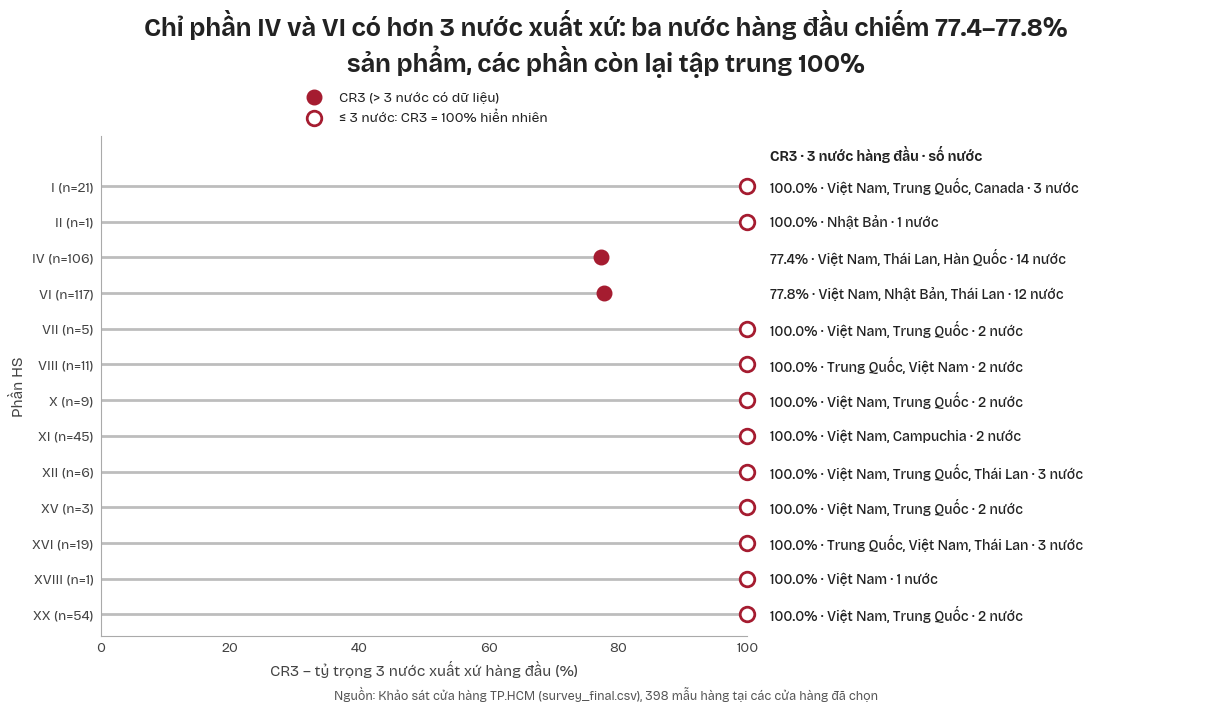

In [ ]:
# [C06C] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU ẢNH
# ---- THAM SỐ ----
HS_SECTIONS_C   = None     # None = tất cả; hoặc ["IV", "VI"]
TOP_K           = 3        # CR3 → đổi 2 hoặc 5 để ra CR2 / CR5
SORT_BY         = "hs"     # "hs" = I → XX ; "cr" = giảm dần theo CR
ONLY_VERIFIED_C = False
COLOR_C         = VN_COLOR
ACTION_TITLE_C  = ("Chỉ phần IV và VI có hơn 3 nước xuất xứ: ba nước hàng đầu chiếm 77.4–77.8% sản phẩm, "
                   "các phần còn lại tập trung 100%")
NOTE_C          = ""
FILE_C          = "C06C_cr3_theo_hs.png"

cr_c06c, df_c06c = prep_c06c(df, HS_SECTIONS_C, TOP_K, ONLY_VERIFIED_C, SORT_BY)
print("n =", len(df_c06c), "| cần xác minh:", (df_c06c.verify_status != "OK").sum())
display(cr_c06c.round(1))

fig_c06c, ax_c06c = plot_c06c(cr_c06c, ACTION_TITLE_C, TOP_K, COLOR_C, note=NOTE_C)
with apply_style():
    fig_c06c.savefig(OUT / FILE_C, dpi=300)
plt.show()

**Insight & kết luận (C06C)**
- Chỉ hai phần có đủ nhiều nước xuất xứ để CR3 có ý nghĩa: IV (14 nước, CR3 = 77.4%: Việt Nam, Thái Lan, Hàn Quốc) và VI (12 nước, CR3 = 77.8%: Việt Nam, Nhật Bản, Thái Lan).
- Mười một phần còn lại chỉ có 1–3 nước nên CR3 = 100% hiển nhiên, không phản ánh mức tập trung thật.

**Hạn chế:** CR3 nhạy với số mẫu; phần có n nhỏ (II, XVIII, XV...) không diễn giải được. Mẫu 398 hàng tại các cửa hàng đã chọn, không suy rộng thị phần TP.HCM. Mẫu `Cần xác minh` vẫn được giữ trong hình.